---
title: Homework 4 - Visualizing fire scars through false color
subtitle: "Repository: https://github.com/olivrwitt/eds220-hwk4.git"
author: Oliver Witt
date: Nov 2026
---

## Preparation: Import Packages

In [ ]:
# First step - Import Packages
# Core python packages for working with datasets
import os
import numpy as np
import pandas as pd

# For plotting
import matplotlib.pyplot as plt

# Needed to import and work with the fire perimeter shapefiles
import geopandas as gpd

# Needed to import and work with the satellite imagery
import xarray as xr

## Import and Explore Fire Perimeter Data
First we need to load the Eaton and Palisades fire perimeter shapefiles.  We need to make sure they have the same CRS (Coordinate Reference System) so that they can be effectively mapped.

In [2]:
# Fire perimeter data exploration
# Read in data
fp = os.path.join("data", "Eaton_Perimeter_20250121", "Eaton_Perimeter_20250121.shp")
eaton = gpd.read_file(fp)
fp = os.path.join("data", "Palisades_Perimieter_20250121", "Palisades_Perimieter_20250121.shp")
palisades = gpd.read_file(fp)

In [3]:
# Check if the crs match
eaton.crs == palisades.crs

True

In [4]:
# Check the eaton crs - is it projected or geographic?
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [5]:
# Check the palisades crs - is it projected or geographic?
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

The fire perimeter data consists of two shapefiles: one for each fire.  These will likely need to be combined later in the analysis.  Both fire perimeter shapefiles use the same CRS: NAD83, EPSG:4269.  For both, this is a geographic 2D CRS.  We can confirm that the CRS of both shapefiles match, meaning transformation will not be necessary.

In [ ]:
# Look at the variables and data types of the eaton perimeter file
eaton.dtypes

OBJECTID         int64
YEAR_            int64
STATE           object
AGENCY          object
UNIT_ID         object
FIRE_NAME       object
type            object
INC_NUM         object
IRWINID         object
ALARM_DATE      object
CONT_DATE       object
CAUSE            int64
C_METHOD         int64
OBJECTIVE        int64
GIS_ACRES      float64
COMMENTS        object
COMPLEX_NA      object
COMPLEX_ID      object
FIRE_NUM        object
GlobalID        object
DECADES         object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object

In [8]:
# Look at the variables and data types of the palisades perimeter file
palisades.dtypes

OBJECTID         int64
YEAR_            int64
STATE           object
AGENCY          object
UNIT_ID         object
FIRE_NAME       object
type            object
INC_NUM         object
IRWINID         object
ALARM_DATE      object
CONT_DATE       object
CAUSE            int64
C_METHOD         int64
OBJECTIVE        int64
GIS_ACRES      float64
COMMENTS        object
COMPLEX_NA      object
COMPLEX_ID      object
FIRE_NUM        object
GlobalID        object
DECADES         object
Shape__Are     float64
Shape__Len     float64
geometry      geometry
dtype: object

It looks like both the Eaton and Palisades fire perimeter files contain the same columns/data tyoes.  This includes records of the year, date, and cause of the fire; as well as the fire name and location.  Both files also contain the geometry of the fire perimeter, as well as a column labeled "GIS_ACRES" (float64), which I presume records the amount of land burned in acres.

## Import and Explore NetCDF Data
Load the satellite data using `xr.open_dataset`, followed by preliminary data exploration.

In [13]:
# Import the Landsat data
landsat = xr.open_dataset("data/landsat8-2025-02-23-palisades-eaton.nc")

In [14]:
# Explore Landsat data
landsat.head()

<xarray.Dataset> Size: 596B
Dimensions:      (y: 5, x: 5)
Coordinates:
  * y            (y) float64 40B 3.799e+06 3.799e+06 ... 3.799e+06 3.799e+06
  * x            (x) float64 40B 3.344e+05 3.344e+05 ... 3.345e+05 3.345e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 100B ...
    green        (y, x) float32 100B ...
    blue         (y, x) float32 100B ...
    nir08        (y, x) float32 100B ...
    swir22       (y, x) float32 100B ...
    spatial_ref  int64 8B ...

In [ ]:
# Look at data types
landsat.dtypes

Frozen({'red': dtype('float32'), 'green': dtype('float32'), 'blue': dtype('float32'), 'nir08': dtype('float32'), 'swir22': dtype('float32'), 'spatial_ref': dtype('int64')})

In [30]:
# How many rows?
len(landsat)

6

In [35]:
# Overview of the dataset
landsat.info

<bound method Dataset.info of <xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...>

Based on this preliminary exploration, we can see that the landsat dataset is an xarray dataset with 6 variables (red, green, blue, nir08, swir22, and spatial_ref).  The first 5 contain information as floats, while spatial_ref contains information as integers.  The dataset also contains x and y corrdinates as floats, and a time component.

## Restore Geospatial Information to NetCDF Data
In order to effectively map this satellite imagery alongside the fire perimeters, it needs to have geospatial attributes

In [ ]:
# Print the CRS of the landsat dataset
print(landsat.rio.crs)

None


Based on the output of `landsat.rio.crs` ("none"), it appears that this dataset is not a geospatial object in its current format.

In [41]:
# Print CRS by accessing `spatial_ref.crs_wkt` attribute
landsat.spatial_ref.crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

Accessing the `spatial_ref.crs_wkt` attribute of the landsat data, we can now see that the CRS is projected, using WGS84.

In [43]:
# Recover the geospatial information by using `rio.write_crs()` and the spatial reference information
landsat = landsat.rio.write_crs(landsat.spatial_ref.crs_wkt)

In [44]:
# Print the CRS to ensure that the above cell worked correctly
print(landsat.rio.crs)

EPSG:32611


This result ("EPSG:32611") matches the CRS information from spatial_ref.crs_wkt.  This means the dataset now has the desired CRS.

## Create and Plot a True Color Image

/Applications/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


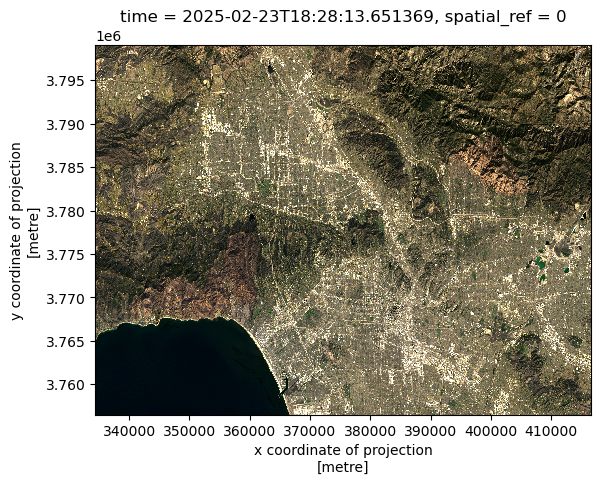

In [ ]:
# Create initial true color image
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

In [58]:
# Look for NA values
np.isnan(landsat).any()
# It looks like there are NAs in the green and blue bands

<xarray.Dataset> Size: 21B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          bool 1B False
    green        bool 1B False
    blue         bool 1B False
    nir08        bool 1B False
    swir22       bool 1B False

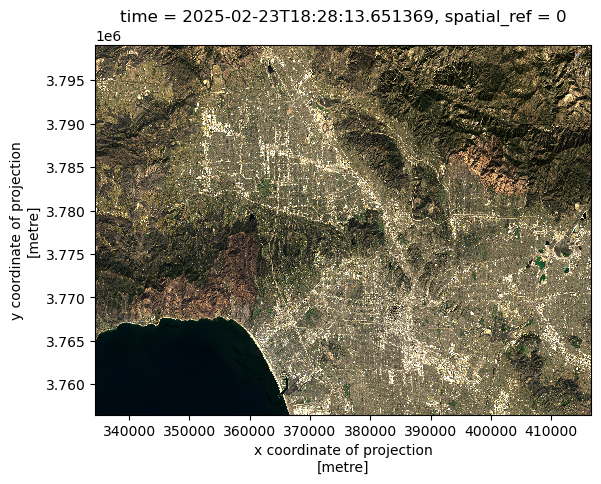

In [62]:
# Replace NA values with zero
landsat = landsat.fillna(0)

# Plot new true color image
truecolor = landsat[['red', 'green', 'blue']].to_dataarray()
truecolor.plot.imshow(robust = True)

##  Create and Plot a False Color Image
We want to use the following correlations, because burned areas heavily reflect SWIR (short wave infrared): Red->SWIR, Green->NIR, Blue->Red

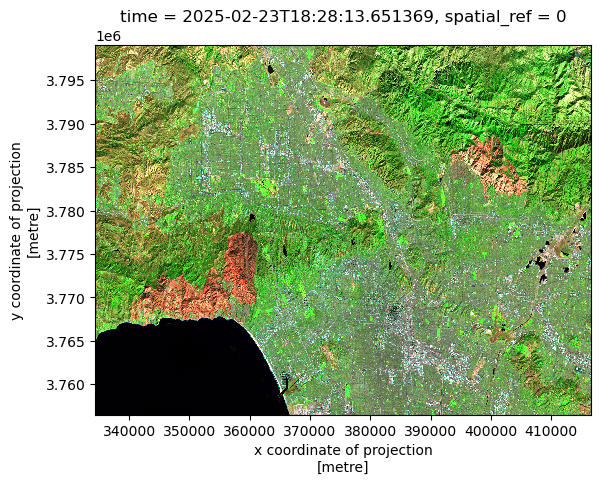

In [ ]:
# Plot a false color image by plotting shortwave infrared, near infrared, red in that order
falsecolor = landsat[['swir22', 'nir08', 'red']].to_dataarray()
falsecolor.plot.imshow(robust = True)

##  Final Map

In [ ]:
# Before we make the map, we have to make sure that the fire perimeters and the false color image have the same CRS.

print(f"Eaton fire perimeter CRS: {eaton.crs}")
print(f"Palisades fire perimeter CRS: {palisades.crs}")
print(f"Landsat image CRS: {landsat.rio.crs}")

Eaton fire perimeter CRS: EPSG:4269
Palisades fire perimeter CRS: EPSG:4269
Landsat image CRS: EPSG:32611


In [91]:
# They do not have the same CRS, so we need to transform 
# We are going to transform the fire perimeters to match the landsat CRS
eaton = eaton.to_crs("EPSG:32611")
palisades = palisades.to_crs("EPSG:32611")

# Now, check that all components have the same CRS
print(f"Eaton fire perimeter CRS: {eaton.crs}")
print(f"Palisades fire perimeter CRS: {palisades.crs}")
print(f"Landsat image CRS: {landsat.rio.crs}")

Eaton fire perimeter CRS: EPSG:32611
Palisades fire perimeter CRS: EPSG:32611
Landsat image CRS: EPSG:32611


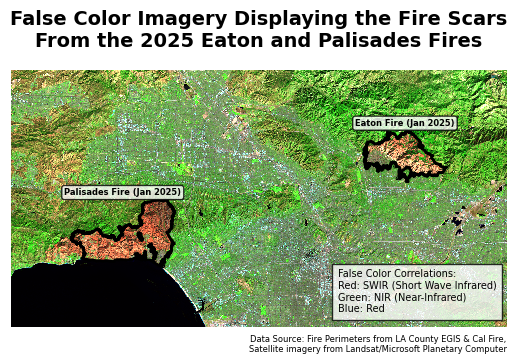

In [140]:
# Map the false color image with fire perimeters
fig, ax = plt.subplots()
ax.axis('off')

# Plot the false color image as the base map
falsecolor.plot.imshow(robust = True)

# Add the fire outlines
eaton.plot(ax=ax, edgecolor = 'black', linewidth = 2, label = 'Eaton Fire Perimeter', facecolor = 'None')
palisades.plot(ax=ax, edgecolor = 'black', linewidth = 2, label = 'Palisades Fire Perimeter', facecolor = 'None')

# Set title with linebreak and bold text
ax.set_title('False Color Imagery Displaying the Fire Scars\nFrom the 2025 Eaton and Palisades Fires', fontsize=14, fontweight='bold')

# Add in-map labels to the fire scars
minx, miny, maxx, maxy = eaton.total_bounds
ax.text(
    (minx + maxx) / 2, maxy + 500,
    'Eaton Fire (Jan 2025)',
    ha='center', va='bottom',
    fontsize=6, color='black', fontweight='bold', 
    bbox=dict(
        facecolor='white',
        alpha=0.8,
        edgecolor='black',
        boxstyle='round,pad=0.3'))

minx, miny, maxx, maxy = palisades.total_bounds
ax.text((minx + maxx) / 2, maxy + 500,
        'Palisades Fire (Jan 2025)',
        ha='center', va='bottom',
        fontsize=6, color='black', fontweight='bold',
         bbox=dict(
                facecolor='white',
                alpha=0.8,
                edgecolor='black',
                boxstyle='round,pad=0.3'))

# Add data attribution
ax.annotate("Data Source: Fire Perimeters from LA County EGIS & Cal Fire,\nSatellite imagery from Landsat/Microsoft Planetary Computer",
            xy=(1, -0.03), xycoords='axes fraction',  # Bottom-right corner of the axes
            ha='right', va='top', fontsize=6, color='black')

# Add legend describing the false color imagery
ax.text(0.66, 0.05, 'False Color Correlations:\nRed: SWIR (Short Wave Infrared)\nGreen: NIR (Near-Infrared)\nBlue: Red',
        transform=ax.transAxes, fontsize=7, va='bottom',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='black'))

plt.show()

## Map Description
This map utilizes false color satellite imagery to visualize the burn scars left by the 2025 Eaton and Palisades fires in Los Angeles, California.  Burn scars show up as prominent red patches, while vegetated areas reflect green.  Burn scars can be difficult to distinguish from dry/bare soil in a true color image.  Therefore, we utilized false color imagery in which the SWIR (Short Wave Infrared) band was visulized as red, so that the burned patches show up as prominent red patches since burned land preferentially reflects SWIR.  Additionally, we visualized the NIR (Near-Infrared) band as green.  NIR reflects off vegetation, and NIR reflection drops significantly in burned areas.

Geographically, this map depicts Los Angeles county.  The black section in the bottom left corner is the Pacific Ocean, bordering on Santa Monica directly below the Palisades Fire burn scar.  The map is roughly centered on downtown Los Angeles.

## About This Assignment
### Purpose
This document contains code and analysis necessary to visualizing fire scars through false color imagery, focusing on the Eaton and Palisades Fires which burned large sections of Los Angeles County in January 2025.  This task explores using python to work with remote sensing data, manipulate false color imagery, and explore how coding and data visualization support environmental monitoring.  The final output is a detailed map displaying the perimeters of the Eaton and Palisades fires overlayed on a false color satellite image of Los Angeles.

### Highlights
This task highlights a workflow and use case for generating a false color image, choosing bands to best visualize the problem at hand.  In this case, to best visualize a wildfire burn scar, we displayed the SWIR (Short Wave Infrared) band as red so that the burn scars showed up as prominent red patches.

This task also highlights _why_ false color imagery is useful.  By first generating a true color image followed by a false color image, we have a direct comparison that visualizes how false color imagery can display certain land characteristics (in this case, burned land) far better than a true color image.

Finally, this task highlights how to create an effective visualization that uses multiple different types of data, and the transformation steps needed to do so.  This is shown through matching and transforming data CRS and using `rio.write_crs()` to recover geospatial attributes of an `xarray`.

### About the data: 
Data is stored in the "data" folder in the repository `eds220-hwk4`, linked in the header but also here: https://github.com/olivrwitt/eds220-hwk4.git.  The `landsat8-2025-02-23-palisades-eaton.nc` data set is a simplified collection of bands (red, green, blue, near-infrared and shortwave infrared) from the Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data, collected by the Landsat 8 satellite.  This data is sourced from the Microsoft Planetary Computer data catalog (https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2).

The Eaton and Palisades shapefiles contain the perimeters of the burned areas resulting from the corresponding fire.
These datasets were downloaded from the County of Los Angeles Enterprise GIS official website (https://egis-lacounty.hub.arcgis.com).  The original data came from CAL FIRE's Historical Fire Perimeter Dataset (https://services1.arcgis.com/jUJYIo9tSA7EHvfZ/arcgis/rest/services/California_Historic_Fire_Perimeters/FeatureServer). 

### References
Eaton and Palisades fire perimeter data sourced from:
“Palisades and Eaton Dissolved Fire Perimeters (2025).” County Of Los Angeles Enterprise GIS, January 21, 2025. https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about. 

The Landsat satellite band data is sourced from the Microsoft Planetary Computer data catalog:
“Microsoft Planetary Computer.” Landsat Collection 2 Level-2. Accessed November 16, 2026. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2. 